In [ ]:
import json
import re
from collections import Counter
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.core import Composition, Element

TIER1_TOXIC = ["Cd", "Hg", "Pb", "Tl", "As", "Be"]
TIER2_CAUTION = ["Cr", "Ni", "Co", "V", "Sb", "Te", "Se", "Ba"]
REMOVE_RADIOACTIVE = True
REMOVE_TIER2 = False
EXTRA_EXCLUDE =[]

RADIOACTIVE = {el.symbol for el in Element if el.Z in (43, 61) or el.Z >= 84}

HERE = Path.cwd()
candidates = [HERE / "data",
              HERE,
              HERE / "nootebooks" / "data" / "data",
              HERE / "notebook" / "data"
              ]

DATA_DIR = next((p for p in candidates if (p / "BandEdge.csv").exists()), None)
assert DATA_DIR is not None, "BandEdge.csv not found. Run the BandEdge.ipynb first."

IN_PATH = DATA_DIR / "BandEdge.csv"
OUT_PATH = DATA_DIR / "Toxicity.csv"
FIG_DIR = DATA_DIR.parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Input:", IN_PATH)
print("Output:", OUT_PATH.name)

Input: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\BandEdge.csv
Output: Toxicity.csv


In [66]:
df = pd.read_csv(IN_PATH)
print("BandEdge.csv shape", df.shape)

def get_elements(row):
    el = row.get("elements")
    if isinstance(el, str) and el.strip():
        return [e for e in re.split(r"[-_]", el) if e]
    try:
        return [e.symbol for e in BandEdge(row["formula"]).elements]
    except Exception:
        return[]
assert ("elements" in df.columns) or ("formula" in df.colums), "Need an elements or formula."
df["element_list"] = df.apply(get_elements, axis=1)
print("Rows with no element information:", int((df["element_list"].str.len() == 0).sum()))

BandEdge.csv shape (1949, 24)
Rows with no element information: 0


In [67]:
remove_set = set(TIER1_TOXIC) | set(EXTRA_EXCLUDE)
if REMOVE_RADIOACTIVE:
    remove_set |= RADIOACTIVE
if REMOVE_TIER2:
    remove_set |= set(TIER2_CAUTION)

def reasons(elements):
    out = []
    for e in elements:
        if e in TIER1_TOXIC:
            out.append(f"toxic:{e}")
        elif e in RADIOACTIVE and REMOVE_RADIOACTIVE:
            out.append(f"radioactive:{e}")
        elif e in TIER2_CAUTION and REMOVE_TIER2:
            out.append(f"caution:{e}")
        elif e in EXTRA_EXCLUDE:
            out.append(f"excludeed:{e}")
    return ";".join(out)

df["removal_reason"] = df["element_list"].apply(reasons)
df["caution_elements"] = df["element_list"].apply(lambda els: ";".join(e for e in els if e in TIER2_CAUTION))

is_removed = df["removal_reason"] != ""
tox_df = df[~is_removed].drop(columns=["element_list", "removal_reason"]).reset_index(drop=True)
removed_df = df[is_removed].drop(columns=["element_list"]).reset_index(drop=True)

n_toxic = int(df["removal_reason"].str.contains("toxic:").sum())
n_radio = int(df["removal_reason"].str.contains("radioactive:").sum())


print("Screening funnel")
print(f"    BandEdge.csv                                        : {len(df):,}")
print(f"    removed, containing toxic element                   : {n_toxic:,}")
print(f"    removed containing radioactive element              : {n_radio:,}")
print(f"    removed in total                                    :{len(removed_df):,}")
print(f"    kept (Toxicity.csv)                                 :  {len(tox_df):,} ({len(tox_df) / len(df):.1%})")

caution_count = int((tox_df["caution_elements"] != "").sum())
print(f"    kept but with a caution element                     :{caution_count:,} ")

per_element = Counter(e for els in df["element_list"] for e in set(els) if e in remove_set)
print()
print("Materials containing each removed element:")
print(pd.Series(per_element).sort_values(ascending=False).to_string())

    


Screening funnel
    BandEdge.csv                                        : 1,949
    removed, containing toxic element                   : 253
    removed containing radioactive element              : 73
    removed in total                                    :324
    kept (Toxicity.csv)                                 :  1,625 (83.4%)
    kept but with a caution element                     :408 

Materials containing each removed element:
Pb    92
Tl    88
Cd    32
U     30
Hg    23
Pa    20
As    19
Th    15
Be    14
Pm     5
Ac     3
Tc     2


In [77]:
print("Rows to save:", len(tox_df), "kept |", len(removed_df), "removed")
print("OUT_PATH is:", repr(OUT_PATH))

tox_df.to_csv(OUT_PATH, index=False)
removed_df.to_csv(REMOVED_PATH, index=False)

for p in (OUT_PATH, REMOVED_PATH):
    print(p.resolve(), "exists:", p.exists(), "| size:", p.stat().st_size if p.exists() else None)

Rows to save: 1625 kept | 324 removed
OUT_PATH is: WindowsPath('c:/Users/solom/Desktop/SemiconductorProject/notebook/data/data/Toxicity.csv')
C:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Toxicity.csv exists: True | size: 421756
C:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Toxicity_removed.csv exists: True | size: 88062


Saved: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Toxicity.csv
Files existe: True
{
  "saved_at": "2026-10-31T01:13:48",
  "input_file": "BandEdge.csv",
  "output_file": "Toxicity.csv",
  "tier1_toxic": [
    "Cd",
    "Hg",
    "Pb",
    "Tl",
    "As",
    "Be"
  ],
  "tier2_caution": [
    "Cr",
    "Ni",
    "Co",
    "V",
    "Sb",
    "Te",
    "Se",
    "Ba"
  ],
  "tier2_removed": false,
  "radioactive_removed": true,
  "rows_in": 1949,
  "removed_toxic": 253,
  "removed_radioactive": 73,
  "row_kept": 1625,
  "row_removed": 324,
  "kept_with_caution_element": 408
}


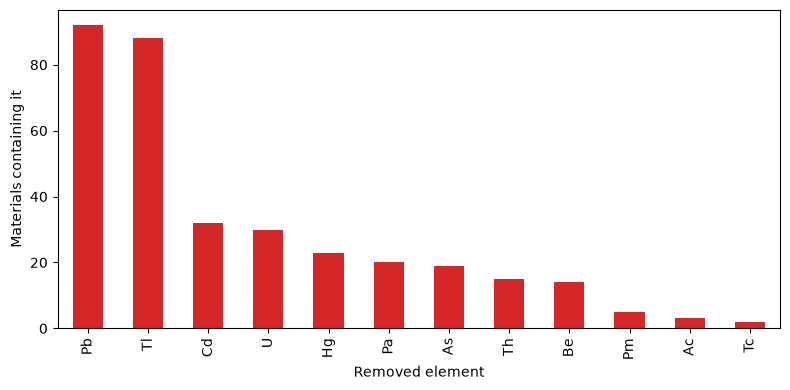

In [78]:
summary = {
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": IN_PATH.name,
    "output_file": OUT_PATH.name,
    "tier1_toxic": TIER1_TOXIC,
    "tier2_caution": TIER2_CAUTION,
    "tier2_removed": REMOVE_TIER2,
    "radioactive_removed": REMOVE_RADIOACTIVE,
    "rows_in": int(len(df)),
    "removed_toxic": n_toxic,
    "removed_radioactive": n_radio,
    "row_kept": int(len(tox_df)),
    "row_removed": int(len(removed_df)),
    "kept_with_caution_element": int((tox_df["caution_elements"] != "").sum()),
   
}
(DATA_DIR / f"{OUT_PATH.stem}_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved:", OUT_PATH)
print("Files existe:", OUT_PATH.exists())
print(json.dumps(summary, indent=2))


top = pd.Series(per_element).sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 4))
top.plot.bar(ax=ax, color="tab:red")
ax.set_xlabel("Removed element"); ax.set_ylabel("Materials containing it");
plt.tight_layout()
plt.savefig(FIG_DIR / "toxicity_screening.png", dpi=200)
plt.show()



